In [34]:
import sys

from pyexpat import model

print(sys.executable)

C:\Users\jyoth\PycharmProjects\NLP\.venv\Scripts\python.exe


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

In [36]:
df=pd.read_csv(r'C:\Users\jyoth\PycharmProjects\NLP\data\output.csv')
df

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
...,...,...
995,I think food should have flavor and texture an...,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go b...,0
998,"The whole experience was underwhelming, and I ...",0


In [37]:
df.columns=['Text','Output']

In [38]:
df

,Text,Output
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1
...,...,...
995,I think food should have flavor and texture an...,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go b...,0
998,"The whole experience was underwhelming, and I ...",0


In [39]:
df.shape

(1000, 2)

In [40]:
df.columns

Index(['Text', 'Output'], dtype='str')

In [41]:
df.head()

,Text,Output
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [42]:
df.tail()

,Text,Output
995,I think food should have flavor and texture an...,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go b...,0
998,"The whole experience was underwhelming, and I ...",0
999,"Then, as if I hadn't wasted enough of my life ...",0


In [43]:
df.isna().sum()

Text      0
Output    0
dtype: int64

In [44]:
df.dtypes

Text        str
Output    int64
dtype: object

In [45]:
df1=df['Output'].value_counts()
df1

Output
1    500
0    500
Name: count, dtype: int64

Text(0.5, 1.0, 'Emotion Count')

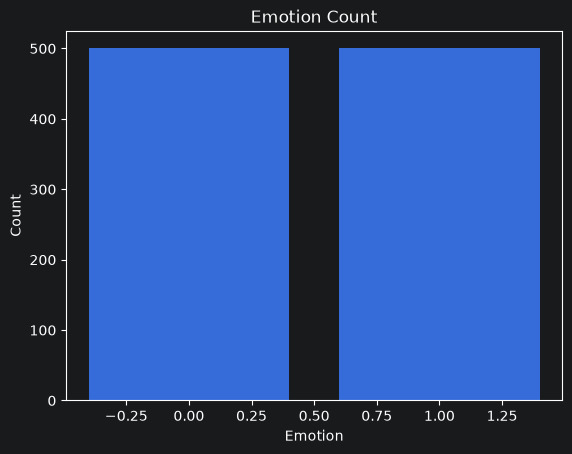

In [46]:
plt.bar(df1.index,df1.values)
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.title('Emotion Count')

In [47]:
tweets=df['Text']
tweets

0                               Wow... Loved this place.
1                                     Crust is not good.
2              Not tasty and the texture was just nasty.
3      Stopped by during the late May bank holiday of...
4      The selection on the menu was great and so wer...
                             ...                        
995    I think food should have flavor and texture an...
996                             Appetite instantly gone.
997    Overall I was not impressed and would not go b...
998    The whole experience was underwhelming, and I ...
999    Then, as if I hadn't wasted enough of my life ...
Name: Text, Length: 1000, dtype: str

In [48]:
from nltk.tokenize import TweetTokenizer
tk=TweetTokenizer()
tweets=tweets.apply(lambda x:tk.tokenize(x)).apply(lambda x:' '.join(x))
tweets


0                             Wow ... Loved this place .
1                                    Crust is not good .
2             Not tasty and the texture was just nasty .
3      Stopped by during the late May bank holiday of...
4      The selection on the menu was great and so wer...
                             ...                        
995    I think food should have flavor and texture an...
996                            Appetite instantly gone .
997    Overall I was not impressed and would not go b...
998    The whole experience was underwhelming , and I...
999    Then , as if I hadn't wasted enough of my life...
Name: Text, Length: 1000, dtype: str

In [49]:
tweets=tweets.apply(lambda x:re.sub('[^a-zA-Z1-9]',' ',x))
tweets

0                             Wow     Loved this place  
1                                    Crust is not good  
2             Not tasty and the texture was just nasty  
3      Stopped by during the late May bank holiday of...
4      The selection on the menu was great and so wer...
                             ...                        
995    I think food should have flavor and texture an...
996                            Appetite instantly gone  
997    Overall I was not impressed and would not go b...
998    The whole experience was underwhelming   and I...
999    Then   as if I hadn t wasted enough of my life...
Name: Text, Length: 1000, dtype: str

In [50]:
# tweets=tweets.apply(lambda x:' '.join([w for w in tk.tokenize(x) if len(w)>=3]))
# tweets

In [51]:
tweets = tweets.apply(
    lambda x: [w for w in tk.tokenize(x) if len(w) >= 3]
).apply(
    lambda x: ' '.join(x)
)
tweets

0                                   Wow Loved this place
1                                         Crust not good
2               Not tasty and the texture was just nasty
3      Stopped during the late May bank holiday off R...
4      The selection the menu was great and were the ...
                             ...                        
995    think food should have flavor and texture and ...
996                              Appetite instantly gone
997         Overall was not impressed and would not back
998    The whole experience was underwhelming and thi...
999    Then hadn wasted enough life there they poured...
Name: Text, Length: 1000, dtype: str

In [52]:
from nltk.stem import SnowballStemmer
st=SnowballStemmer('english')
tweets=tweets.apply(lambda x:[st.stem(i.lower()) for i in tk.tokenize(x)]).apply(lambda x:' '.join(x))
tweets

0                                    wow love this place
1                                         crust not good
2                not tasti and the textur was just nasti
3      stop dure the late may bank holiday off rick s...
4       the select the menu was great and were the price
                             ...                        
995    think food should have flavor and textur and b...
996                                 appetit instant gone
997            overal was not impress and would not back
998    the whole experi was underwhelm and think just...
999    then hadn wast enough life there they pour sal...
Name: Text, Length: 1000, dtype: str

In [53]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jyoth\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [54]:
from nltk.corpus import stopwords
sp=stopwords.words('english')
tweets=tweets.apply(lambda x:[i for i in tk.tokenize(x) if i not in sp]).apply(lambda x:' '.join(x))
tweets

0                                         wow love place
1                                             crust good
2                                     tasti textur nasti
3      stop dure late may bank holiday rick steve rec...
4                                select menu great price
                             ...                        
995                        think food flavor textur lack
996                                 appetit instant gone
997                            overal impress would back
998    whole experi underwhelm think ninja sushi next...
999    wast enough life pour salt wound draw time too...
Name: Text, Length: 1000, dtype: str

In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer
vec=TfidfVectorizer()
data=vec.fit_transform(tweets)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5436 stored elements and shape (1000, 1540)>

In [56]:
print(data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5436 stored elements and shape (1000, 1540)>
  Coords	Values
  (0, 1523)	0.7681483384958535
  (0, 791)	0.5161133452017592
  (0, 1014)	0.37891311005388717
  (1, 325)	0.895377322694293
  (1, 592)	0.44530826402032975
  (2, 1340)	0.5068726783980841
  (2, 1352)	0.6095408468238828
  (2, 889)	0.6095408468238828
  (3, 791)	0.21623578455056802
  (3, 1289)	0.3018243460296966
  (3, 423)	0.3018243460296966
  (3, 753)	0.3360255647440285
  (3, 823)	0.3018243460296966
  (3, 93)	0.35603199517087525
  (3, 661)	0.35603199517087525
  (3, 1129)	0.35603199517087525
  (3, 1282)	0.35603199517087525
  (3, 1097)	0.2449489159152951
  (4, 1184)	0.5638600054619226
  (4, 841)	0.5339527493828152
  (4, 606)	0.3882226113218433
  (4, 1047)	0.4962253114518262
  (5, 576)	0.3493612006084169
  (5, 35)	0.546476954759213
  (5, 1473)	0.38439817982521884
  :	:
  (996, 52)	0.595797388951357
  (996, 711)	0.595797388951357
  (997, 1521)	0.45350164055848285
  (997, 84)

In [57]:
y=df['Output'].values

In [58]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(data,y,test_size=0.30,random_state=42)


In [59]:
from sklearn.neighbors import KNeighborsClassifier
model=KNeighborsClassifier(n_neighbors=7)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
y_pred

array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0,
       1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1])

In [60]:
from sklearn.metrics import classification_report
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.70      0.82      0.76       152
           1       0.77      0.65      0.71       148

    accuracy                           0.73       300
   macro avg       0.74      0.73      0.73       300
weighted avg       0.74      0.73      0.73       300



In [61]:
sent=['satisfied']
num=vec.transform(sent)
pred1=model.predict(num)
pred1[0]

np.int64(0)

In [62]:
#streamlit

In [63]:
import joblib

In [64]:
saved_data={
    "model":model,
    "vectorizer":vec
}

joblib.dump(saved_data,"models/nlp_model.pkl")

['models/nlp_model.pkl']